# 🚀 Practice Day 44

**📅 Date:** **2026-10-27**  
**📁 Category:** **Phase 1 · NumPy 기초 (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice vectorized NumPy operations by implementing a parking fee formula with a free grace period and a daily cap
  (무료 유예시간과 일 상한이 있는 주차 요금 계산식을 벡터화된 NumPy 연산으로 구현하며 배열 연산 연습하기)
- Find how fees are distributed, how many stays hit the daily cap, and what the average fee is
  (요금이 어떻게 분포하는지, 일 상한에 도달한 건수는 몇 건인지, 평균 요금은 얼마인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Parking Fee Calculation (Duration-Based, Capped) / 주차장 요금 계산 데이터 (구간별 요금 + 일 상한)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 230 parking sessions — single table with only `parking_id` and `duration_minutes`. Fees are in USD. The fee needs to be computed with vectorized array operations using the rate structure below.

**Rate structure / 요금 구조:**
- First 30 minutes: free (최초 30분 무료)
- After that: $0.50 per 10-minute block, rounded up (30분 이후 10분당 $0.50, 올림 적용)
- Daily cap: $15 maximum regardless of duration (일 최대 $15 상한)

(230건의 주차 세션 데이터입니다 — parking_id와 duration_minutes만 있는 단일 테이블이며, 요금은 USD이고 위 요금 구조를 벡터화 연산으로 직접 계산해야 합니다.)

## Dataset Preview

In [17]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate parking session durations (fee is NOT precomputed) ---
n = 230

# mixture: ~18% short/free stays, ~57% moderate, ~25% long (likely to hit the cap)
category = rng.choice(['short', 'moderate', 'long'], size=n, p=[0.18, 0.57, 0.25])
duration = np.zeros(n)
for i, c in enumerate(category):
    if c == 'short':
        duration[i] = rng.uniform(5, 30)
    elif c == 'moderate':
        duration[i] = rng.uniform(31, 300)
    else:
        duration[i] = rng.uniform(300, 700)
duration = np.round(duration).astype(int)

df = pd.DataFrame({
    'parking_id': [f'PK{str(i+1).zfill(4)}' for i in range(n)],
    'duration_minutes': duration
})

df.head(10)


,parking_id,duration_minutes
0,PK0001,356
1,PK0002,144
2,PK0003,686
3,PK0004,191
4,PK0005,28
5,PK0006,622
6,PK0007,487
7,PK0008,614
8,PK0009,5
9,PK0010,60


## Dataset Information

In [18]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   parking_id        230 non-null    str  
 1   duration_minutes  230 non-null    int64
dtypes: int64(1), str(1)
memory usage: 3.7 KB

Shape: (230, 2)


,parking_id,duration_minutes
count,230,230.000000
unique,230,NaN
top,PK0001,NaN
freq,1,NaN
mean,NaN,213.139130
std,NaN,187.501005
min,NaN,5.000000
25%,NaN,55.000000
50%,NaN,185.000000
75%,NaN,293.500000


---
# ❓ Business Questions

1. **(Analysis)** Using the rate structure above, what is the fee for each parking session?
   (위 요금 구조를 적용하면, 주차 세션별 요금은 각각 얼마인가?)
2. **(Analysis)** How many sessions hit the daily cap of $15?
   (일 상한 $15에 도달한 세션은 몇 건인가?)
3. **(Analysis)** What is the average fee across all sessions, and how many sessions were free (30 minutes or under)?
   (전체 평균 요금은 얼마이며, 무료(30분 이하) 세션은 몇 건인가?)
4. **(Visualization)** Show the distribution of fees across all sessions.
   (전체 세션의 요금 분포는 어떤 모습인가?)
5. **(Visualization)** Show the relationship between duration and fee — where does the cap become visible?
   (주차 시간과 요금의 관계를 보면, 상한이 어디서 드러나는가?)

---
# 🔍 Data Cleaning Check


In [19]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
parking_id          0
duration_minutes    0
dtype: int64

Duplicate rows: 0

Dtypes
parking_id            str
duration_minutes    int64
dtype: object

Column names
['parking_id', 'duration_minutes']

Text columns — unique counts
parking_id    230
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Using the rate structure, what is the fee for each parking session? (요금 구조 적용 시 세션별 요금은?)

**Result:** A 28-minute stay is **$0**. A 144-minute stay is **$6.00**. A 356-minute stay is **$15**.  
(28분은 $0, 144분은 $6.00, 356분은 $15)

**Insight:** The first 30 minutes add **$0**. Each extra 10-minute block, rounded up, adds **$0.50**, and the fee stops at **$15**.  
(처음 30분은 $0. 이후 10분 블록은 올림해서 $0.50씩 더하고, 요금은 $15에서 멈춤)

In [20]:
# Question 1: compute fee for every row using the rate structure (vectorized - no row-by-row loop)

df['fee'] = np.ceil(np.maximum(0, df['duration_minutes'] - 30) / 10) * 0.5
df['fee'] = np.minimum(df['fee'], 15)

df

,parking_id,duration_minutes,fee
0,PK0001,356,15.0
1,PK0002,144,6.0
2,PK0003,686,15.0
3,PK0004,191,8.5
4,PK0005,28,0.0
...,...,...,...
225,PK0226,373,15.0
226,PK0227,30,0.0
227,PK0228,154,6.5
228,PK0229,242,11.0


## Question 2

**Question:** How many sessions hit the daily cap of $15? (일 상한 $15에 도달한 세션 수는?)

**Result:** **54** sessions have a fee of **$15**.  
($15인 세션은 54건)

**Insight:** Those **54** sessions are **23.5%** of all **230** sessions.  
(54건은 전체 230건의 23.5%)

In [21]:
# Question 2: how many sessions hit the daily cap (fee == 15)

df.groupby('fee').size().loc[15]

np.int64(54)

## Question 3

**Question:** What is the average fee across all sessions, and how many sessions were free? (평균 요금과 무료 세션 수는?)

**Result:** The average fee is **$7.43**. **47** sessions are free.  
(평균 요금은 $7.43. 무료 세션은 47건)

**Insight:** The **47** free sessions are **20.4%** of **230**. The other **183** sessions pay, and **54** of them are already at **$15**.  
(무료 47건은 230건의 20.4%. 나머지 183건은 요금이 있고, 그중 54건은 이미 $15)

In [22]:
# Question 3: average fee overall, and how many sessions were free (duration <= 30 min)
print("average fee:", df['fee'].mean())
print("number of free sessions:", df[df['duration_minutes'] <= 30].shape[0])

average fee: 7.426086956521739
number of free sessions: 47


---
# 📈 Visualization

**Chart 1:** Histogram — distribution of fees (히스토그램: 요금 분포)

*Interpretation:* The tall bars are the two ends: **$0** and **$15**. Those are the **47** free sessions and the **54** capped sessions.  
(높은 막대는 양쪽 끝 $0과 $15. 무료 47건과 상한 54건)

---

**Chart 2:** Scatter plot — duration vs fee, showing the cap (산점도: 주차시간 vs 요금, 상한 구간 확인)

*Interpretation:* The fee rises with duration, then flattens on the **$15** line after the **300**-minute mark. The longest stay, **686** minutes, is on that line.  
(요금은 시간과 함께 오르다가 300분이 지난 뒤 $15 선에서 평평함. 가장 긴 686분도 그 선 위)

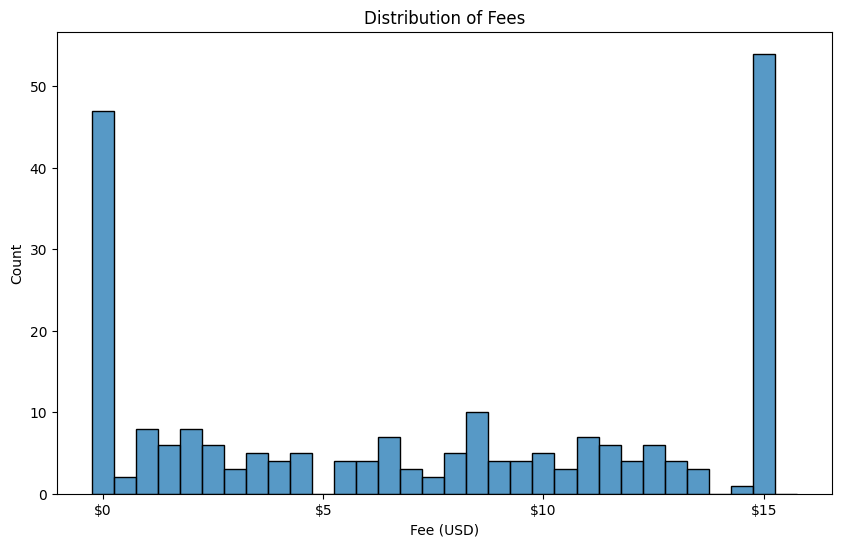

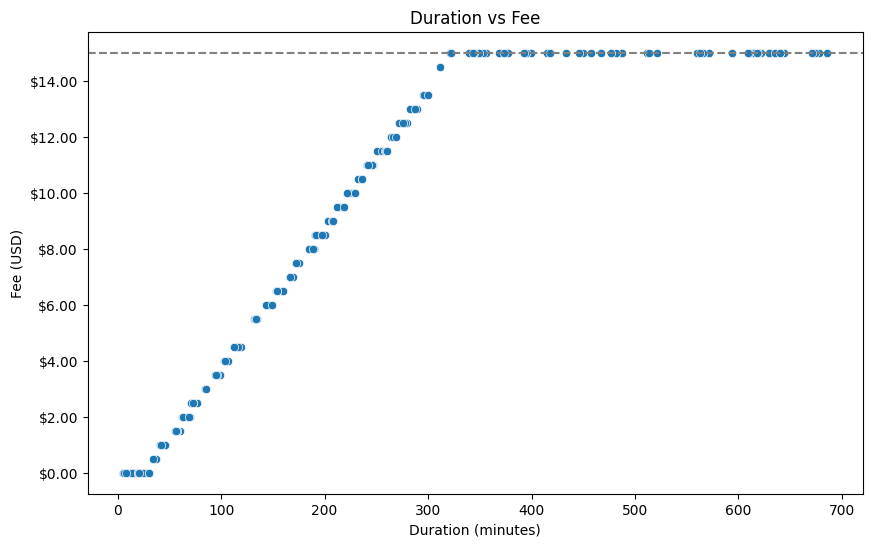

In [23]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: distribution of fees (histogram)
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.arange(-0.25, 15.76, 0.5)
sns.histplot(df['fee'], bins=bins, ax=ax)
ax.set_xticks([0, 5, 10, 15])
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Distribution of Fees')
ax.set_xlabel('Fee (USD)')
ax.set_ylabel('Count')
plt.show()

# Chart 2: duration vs fee (scatter) - should show a flat plateau once the cap kicks in
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x='duration_minutes', y='fee', data=df, ax=ax)
ax.axhline(15, linestyle='--', color='gray')
ax.yaxis.set_major_formatter('${x:,.2f}')
ax.set_title('Duration vs Fee')
ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Fee (USD)')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- **54** of **230** sessions, **23.5%**, already pay the **$15** cap.  
  (230건 중 54건, 23.5%가 이미 상한 $15)
- **47** sessions, **20.4%**, pay **$0** because they stay 30 minutes or less.  
  (47건, 20.4%는 30분 이하라서 $0)
- The average fee is **$7.43**.  
  (평균 요금은 $7.43)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat the **54** capped sessions as a separate group. More time after the cap does not add fee past **$15**.  
   (상한 54건은 따로 볼 것. 상한 이후 시간이 늘어도 요금은 $15를 넘지 않음)
2. The **47** free sessions are inside the 30-minute grace period, so they are not unpaid errors.  
   (무료 47건은 30분 무료 구간 안이라서, 요금이 빠진 오류가 아님)
3. Use **$7.43** as the average fee across all **230** sessions, not the **$15** cap.  
   (전체 230건의 평균 요금은 $7.43. 상한 $15를 평균으로 쓰지 않기)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The fee axes did not say USD.  
  (요금 축에 USD가 없었음)
- Chart 1 used 20 bins, so the **$15** cap sat against the 14 tick instead of on **$15**.  
  (차트 1이 20개 구간이라 $15 상한 막대가 14 눈금 쪽에 붙었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `np.ceil(np.maximum(0, minutes - 30) / 10) * 0.5` is the rounded-up block fee. `np.minimum(..., 15)` applies the cap.  
  (그 식이 10분 블록 올림 요금. `np.minimum(..., 15)`가 상한)
- A fee of **$15** marks the **54** capped sessions. `duration_minutes <= 30` marks the **47** free sessions.  
  (요금 $15가 상한 54건. `duration_minutes <= 30`이 무료 47건)
- A fee chart needs a dollar format. Histogram bins should sit on the **$0.50** steps so **$0** and **$15** stay apart.  
  (요금 차트에는 달러 형식이 필요함. 히스토그램 구간은 $0.50 단위여야 $0과 $15가 갈라짐)  

---
# 🧠 Reflection

**What was difficult?**  
Turning the grace period, the rounded-up 10-minute block, and the **$15** cap into one vectorized line.  
(무료 시간, 10분 올림, $15 상한을 벡터 연산 한 줄로 만드는 것)

**Why?**  
Minutes at or under 30 have to become **$0** before the block count, and the cap is a second step after that fee.  
(30분 이하는 블록 수 전에 $0이 되어야 하고, 상한은 그 요금 다음 단계)

**How did I solve it?**  
Used `np.maximum` so the billable minutes never go below 0, `np.ceil` for the block count, and `np.minimum` for the cap.  
(`np.maximum`으로 청구 분이 0 아래로 안 내려가게 하고, `np.ceil`로 블록 수를 올리고, `np.minimum`으로 상한을 적용)

**What would I do differently next time?**  
Put USD on the fee axis, and set histogram bins on the **$0.50** steps before reading the two tall bars.  
(요금 축에 USD를 두고, 높은 막대 두 개를 읽기 전에 히스토그램 구간을 $0.50 단위로 맞추기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The **$0.50** block, the **$15** cap, and the **54** capped sessions are clear. A fee chart still needs a dollar axis.  
($0.50 블록, $15 상한, 상한 54건은 이해함. 요금 차트는 달러 축이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The fee line was short once the free minutes were removed first. The histogram bins were the hard part.  
(무료 분을 먼저 빼면 요금 식은 짧았음. 어려운 부분은 히스토그램 구간이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 45 — data cleaning (Round 4/5)  
  (정비소 서비스 기록 정제)  